# Augmentations : the basics

`acids_dataset.transforms` gathers its own augmentations and wrappers of
[audiomentations](https://github.com/iver56/audiomentations), with a common interface :

- transforms take `torch.Tensor` or `np.ndarray` inputs of shape `(..., channels, samples)`, and give outputs of the
  same type ;
- they are applied randomly with a probability `p` ;
- they can be composed with `Compose`, and configured with gin files.

In [4]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from acids_dataset import transforms as adt

SR = 16000
torch.manual_seed(0)
t = torch.arange(SR) / SR
x = sum(0.3 / k * torch.sin(2 * math.pi * 220 * k * t) for k in range(1, 8))[None] * torch.exp(-2 * t)

def plot_waves(waves, titles, figsize=(12, 2)):
    fig, axes = plt.subplots(1, len(waves), figsize=figsize, sharey=True)
    for ax, w, title in zip(np.atleast_1d(axes), waves, titles):
        ax.plot(np.arange(np.asarray(w).shape[-1]) / SR, np.asarray(w).reshape(-1, np.asarray(w).shape[-1])[0], lw=0.5)
        ax.set_title(title, fontsize=9); ax.set_xlabel("time (s)")
    plt.show()

## Applying a transform

A transform is a callable. Torch tensors give tensors, numpy arrays give arrays :

Tensor ndarray


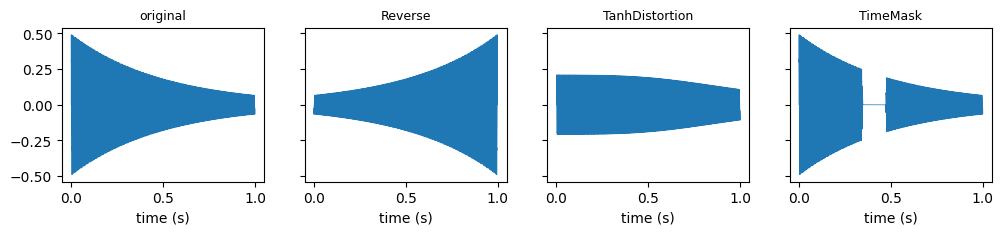

In [5]:
reverse = adt.Reverse(sr=SR)
print(type(reverse(x)).__name__, type(reverse(x.numpy())).__name__)
plot_waves([x, reverse(x), adt.TanhDistortion(sr=SR)(x), adt.TimeMask(sr=SR)(x)],
           ["original", "Reverse", "TanhDistortion", "TimeMask"])

## Probabilities

With `p`, each item of a batch is transformed with probability `p` :

In [6]:
batch = x.expand(1000, 1, -1).clone()                       # 1000 copies of the same item
for p in [0.1, 0.5, 0.9]:
    out = adt.PolarityInversion(p=p, sr=SR)(batch)
    print("p = %.1f -> %.1f%% of items inverted" % (p, 100 * (out[:, 0, 1000] * batch[:, 0, 1000] < 0).float().mean()))

p = 0.1 -> 10.4% of items inverted
p = 0.5 -> 50.7% of items inverted
p = 0.9 -> 90.0% of items inverted


For `acids_dataset` transforms (`Mute`, `RandomEQ`, `Stretch`, ...), `rand_batchwise=True` (default) draws the
decision for each item of the batch, and `rand_batchwise=False` once for the whole call :

In [7]:
for rand_batchwise in [True, False]:
    mute = adt.Mute(p=0.5, rand_batchwise=rand_batchwise, sr=SR)
    muted = [(mute(batch[:8]).abs().amax(-1) < 1e-3).flatten().int().tolist() for _ in range(4)]
    print("rand_batchwise=%-5s muted items of 4 batches : %s" % (rand_batchwise, muted))

rand_batchwise=True  muted items of 4 batches : [[1, 0, 1, 1, 1, 0, 1, 0], [0, 1, 1, 0, 0, 1, 1, 0], [1, 1, 0, 0, 1, 0, 1, 1], [1, 1, 0, 1, 0, 1, 0, 0]]
rand_batchwise=False muted items of 4 batches : [[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1]]


`_force_transform=True` applies a transform whatever its probability, e.g. to listen to it :

In [8]:
phaser = adt.PhaseMangle(p=0.01, sr=SR)
print("forced :", not torch.allclose(phaser(x, _force_transform=True), x))

forced : True


## Composing transforms

`Compose` applies transforms in sequence. It is a list : transforms can be appended, removed, sliced...
Each transform keeps its own probability, such that a pipeline gives a different combination at each call.

6 transforms : ['RandomEQ', 'TanhDistortion', 'AddGaussianSNR', 'Gain', 'Mute', 'PolarityInversion']


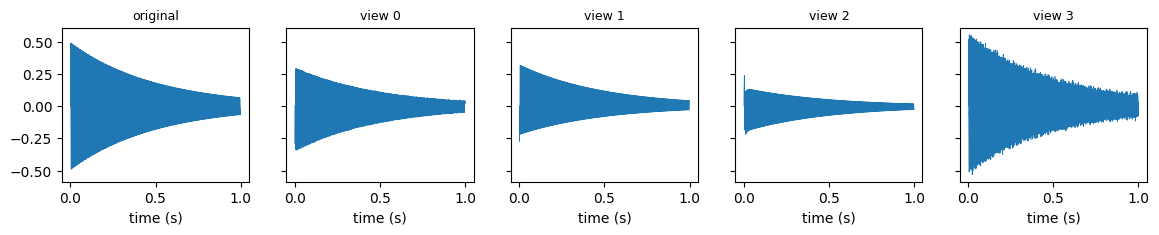

In [9]:
pipeline = adt.Compose(
    adt.RandomEQ(p=0.8, sr=SR),               # random filters
    adt.TanhDistortion(p=0.3, sr=SR),
    adt.AddGaussianSNR(p=0.5, sr=SR),          # noise at a random SNR
    adt.Gain(p=0.8, sr=SR),
    adt.Mute(p=0.1, sr=SR),                    # forces models to learn silence
)
pipeline.append(adt.PolarityInversion(p=0.5, sr=SR))
print(len(pipeline), "transforms :", [type(tr).__name__ for tr in pipeline])

views = [pipeline(x) for _ in range(4)]
plot_waves([x] + views, ["original"] + ["view %d" % i for i in range(4)], figsize=(14, 2))
for v in views[:2]:
    display(Audio(v[0].numpy(), rate=SR))

## Configuration files

Each transform has a gin configuration in `acids_dataset/configs/transforms`, used by presets and by the command line
(`acids-dataset preprocess ... --transform gain`), and that can be copied and customized :

In [10]:
from pathlib import Path
import acids_dataset
config_dir = Path(acids_dataset.__file__).parent / "configs" / "transforms"
print(sorted(p.stem for p in config_dir.glob("*.gin"))[:12], "...")
print((config_dir / "randomeq.gin").read_text())

['addbackgroundnoise', 'addcolornoise', 'addgaussiannoise', 'addgaussiansnr', 'addnoise', 'addshortnoises', 'adjustduration', 'airabsorption', 'aliasing', 'applyimpulseresponse', 'bandpassfilter', 'bandstopfilter'] ...

RandomEQ:
	p_lp = 0.75
	p_bp = 0.5
	n_bp = 2
	p_ls = 0.5

transforms.parse_transform:
    transform = @transforms.RandomEQ



### Writing your own augmentation file

A whole pipeline can also be written in a single gin file, by giving the list of transforms to
`transforms.Compose.transforms` and making `transforms.parse_transform` build a `Compose` :

- parameters are set with bindings (`transforms.Mute.p = 0.1`), or with a block `transforms.AddGaussianSNR: ...` ;
- **scopes** (`eq_soft/`, `eq_hard/`) give different parameters to several instances of the same transform ;
- `%SAMPLE_RATE` is a gin constant, set by `acids-dataset` from the dataset's metadata (or by hand below) : the same file
  then works for any sampling rate.

In [11]:
my_augmentations = """
# --- parameters of each transform ---

# two RandomEQ with different parameters, distinguished by scopes
eq_soft/transforms.RandomEQ:
    p = 0.8
    n_bp = 1
    sr = %SAMPLE_RATE

eq_hard/transforms.RandomEQ:
    p = 0.2
    n_bp = 4
    sr = %SAMPLE_RATE

transforms.AddGaussianSNR:
    p = 0.5
    min_snr_db = 15.0
    max_snr_db = 40.0
    sr = %SAMPLE_RATE

transforms.Gain.p = 0.8
transforms.Gain.sr = %SAMPLE_RATE
transforms.Mute.p = 0.1
transforms.Mute.sr = %SAMPLE_RATE

# --- pipeline (applied in this order) ---

transforms.Compose.transforms = [
    @eq_soft/transforms.RandomEQ(),
    @eq_hard/transforms.RandomEQ(),
    @transforms.AddGaussianSNR(),
    @transforms.Gain(),
    @transforms.Mute(),
]

transforms.parse_transform.transform = @transforms.Compose
"""
Path("my_augmentations.gin").write_text(my_augmentations)

778

The file is loaded with `transform_from_gin_config`, which gives back the `Compose`. The same file can be given to
the command line with its path (e.g. `acids-dataset add_embedding ... --transform path/to/my_augmentations.gin`) :

Exception ignored in: <function BaseEventLoop.__del__ at 0x107154a60>
Traceback (most recent call last):
  File "/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/asyncio/base_events.py", line 687, in __del__
    if not self.is_closed():
  File "/Users/domkirke/miniconda3/envs/acidsdataset/lib/python3.10/asyncio/base_events.py", line 684, in is_closed
    return self._closed
AttributeError: '_UnixSelectorEventLoop' object has no attribute '_closed'


Compose ['RandomEQ', 'RandomEQ', 'AddGaussianSNR', 'Gain', 'Mute']
eq_soft : p=0.8, n_bp=1 | eq_hard : p=0.2, n_bp=4


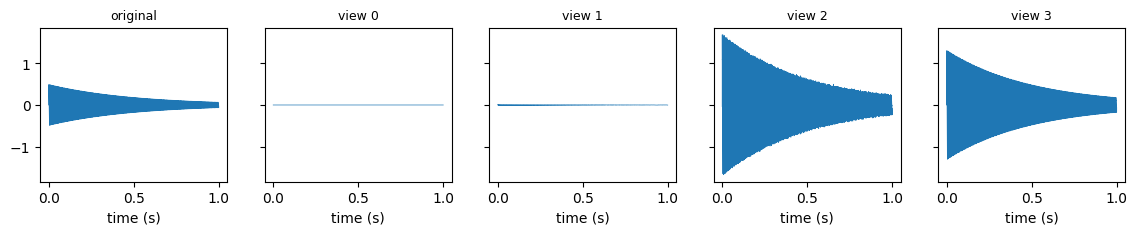

In [12]:
from acids_dataset.utils import transform_from_gin_config, set_gin_constant

set_gin_constant("SAMPLE_RATE", SR)                     # done automatically from dataset metadata
my_pipeline = transform_from_gin_config(str(Path("my_augmentations.gin").resolve()))
print(type(my_pipeline).__name__, [type(tr).__name__ for tr in my_pipeline])
print("eq_soft : p=%s, n_bp=%s | eq_hard : p=%s, n_bp=%s" % (my_pipeline[0].p, my_pipeline[0].n_bp,
                                                           my_pipeline[1].p, my_pipeline[1].n_bp))

views = [my_pipeline(x) for _ in range(4)]
plot_waves([x] + views, ["original"] + ["view %d" % i for i in range(4)], figsize=(14, 2))